# Assignment 2: Patient Readmission Analysis

**Task:** Binary classification: predicting whether a diabetic patient will be readmitted within 30 days of discharge.

- **Positive class (1):** `readmitted == "<30"`
- **Negative class (0):** `readmitted == ">30"` or `"NO"`

**Output:** Probability of early readmission per hospital stay (row).

## 1. Imports & Setup

In [1]:
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    f1_score, precision_score, recall_score, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
DATA_PATH = "diabetes_dev.csv"
MODEL_DIR = "model"
os.makedirs(MODEL_DIR, exist_ok=True)

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head(3)

Shape: (81281, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


## 3. Exploratory Data Analysis (EDA)

### 3.1 Missing Values

The dataset encodes missing values as `"?"` rather than `NaN`. We replace them first before counting.

In [3]:
df.replace("?", np.nan, inplace=True)

missing = df.isnull().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print("Columns with missing values:")
print((missing * 100).round(1).astype(str) + "%")

Columns with missing values:
weight               96.8%
max_glu_serum        94.7%
A1Cresult            83.2%
medical_specialty    49.0%
payer_code           39.6%
race                  2.3%
diag_3                1.4%
diag_2                0.4%
diag_1                0.0%
dtype: object


**Key observations:**
- `weight`: ~97% missing - drop entirely
- `medical_specialty`: ~49% missing - keep, fill with `"Unknown"`
- `max_glu_serum` and `A1Cresult`: very high missingness - drop
- `payer_code`: ~40% missing, low signal - drop

### 3.2 Target Distribution

early readmission (within 30 days) is the clinically actionable window- hospital staff can intervene before discharge if they know a patient is high-risk.

readmitted
NO     43913
>30    28315
<30     9053
Name: count, dtype: int64

Normalized:
readmitted
NO     0.540
>30    0.348
<30    0.111
Name: proportion, dtype: float64

Early readmit (class 1) rate: 0.111


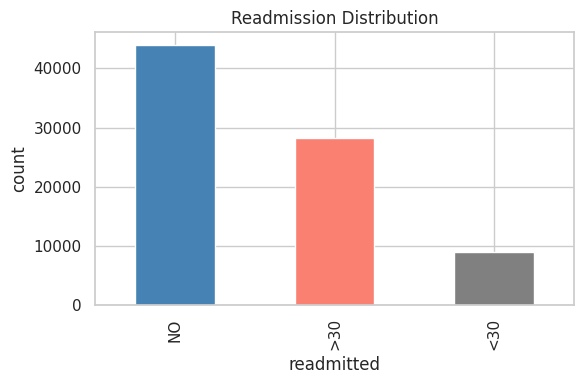

In [4]:
print(df["readmitted"].value_counts())
print("\nNormalized:")
print(df["readmitted"].value_counts(normalize=True).round(3))

df["early_readmit"] = (df["readmitted"] == "<30").astype(int)
print("\nEarly readmit (class 1) rate:", df["early_readmit"].mean().round(3))

fig, ax = plt.subplots(figsize=(6, 4))
df["readmitted"].value_counts().plot(kind="bar", color=["steelblue", "salmon", "gray"], ax=ax)
ax.set_title("Readmission Distribution")
ax.set_xlabel("readmitted")
ax.set_ylabel("count")
plt.tight_layout()
plt.savefig("target_distribution.png", dpi=120)
plt.show()

**Class imbalance:** Only ~11% of stays result in early readmission. This means a naive model that always predicts "No" would achieve 89% accuracy but be completely useless. We use Average Precision (area under the precision-recall curve) as our primary metric, which is more informative under imbalance.

### 3.3 Patient Duplicates, Why Grouped Splitting Matters

In [5]:
print("Total rows:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())
print("Patients with >1 encounter:", (df["patient_nbr"].value_counts() > 1).sum())

Total rows: 81281
Unique patients: 57214
Patients with >1 encounter: 13376


Many patients appear multiple times. If we split randomly by row, the same patient could appear in both train and validation — the model would "remember" that patient and report unrealistically optimistic metrics. We use `GroupShuffleSplit` on `patient_nbr` to ensure each patient appears in only one split.

### 3.4 Diagnosis Codes — ICD-9 Grouping

There are 700+ unique ICD-9 codes across `diag_1`, `diag_2`, `diag_3`. Feeding raw codes into a model is problematic: rare codes have no statistical support and unseen codes in held-out data would crash ordinal encoding. We map them to 9 clinically meaningful categories.

In [6]:
print("diag_1 unique codes:", df["diag_1"].nunique())
print("diag_2 unique codes:", df["diag_2"].nunique())
print("diag_3 unique codes:", df["diag_3"].nunique())

def group_icd9(code):
    if pd.isna(code):
        return "Missing"
    code = str(code).strip()
    if code.startswith("V"):
        return "Other"
    if code.startswith("E"):
        return "Injury"
    try:
        c = float(code)
    except ValueError:
        return "Other"
    if 390 <= c <= 459 or c == 785:   return "Circulatory"
    elif 460 <= c <= 519 or c == 786: return "Respiratory"
    elif 520 <= c <= 579 or c == 787: return "Digestive"
    elif 250 <= c <= 250.99:          return "Diabetes"
    elif 800 <= c <= 999:             return "Injury"
    elif 710 <= c <= 739:             return "Musculoskeletal"
    elif 580 <= c <= 629 or c == 788: return "Genitourinary"
    elif 140 <= c <= 239:             return "Neoplasms"
    else:                              return "Other"

df["diag_1_group"] = df["diag_1"].apply(group_icd9)
print("\ndiag_1 groups:")
print(df["diag_1_group"].value_counts())

diag_1 unique codes: 695
diag_2 unique codes: 723
diag_3 unique codes: 759

diag_1 groups:
diag_1_group
Circulatory        24301
Other              14591
Respiratory        11497
Digestive           7519
Diabetes            6997
Injury              5559
Genitourinary       4130
Musculoskeletal     3962
Neoplasms           2708
Missing               17
Name: count, dtype: int64


### 3.5 Numeric Features Distribution

       time_in_hospital  num_lab_procedures  num_procedures  num_medications  \
count          81281.00            81281.00        81281.00         81281.00   
mean               4.39               43.08            1.34            16.00   
std                2.98               19.67            1.70             8.12   
min                1.00                1.00            0.00             1.00   
25%                2.00               31.00            0.00            10.00   
50%                4.00               44.00            1.00            15.00   
75%                6.00               57.00            2.00            20.00   
max               14.00              129.00            6.00            79.00   

       number_outpatient  number_emergency  number_inpatient  number_diagnoses  
count           81281.00          81281.00          81281.00          81281.00  
mean                0.37              0.20              0.63              7.42  
std                 1.28            

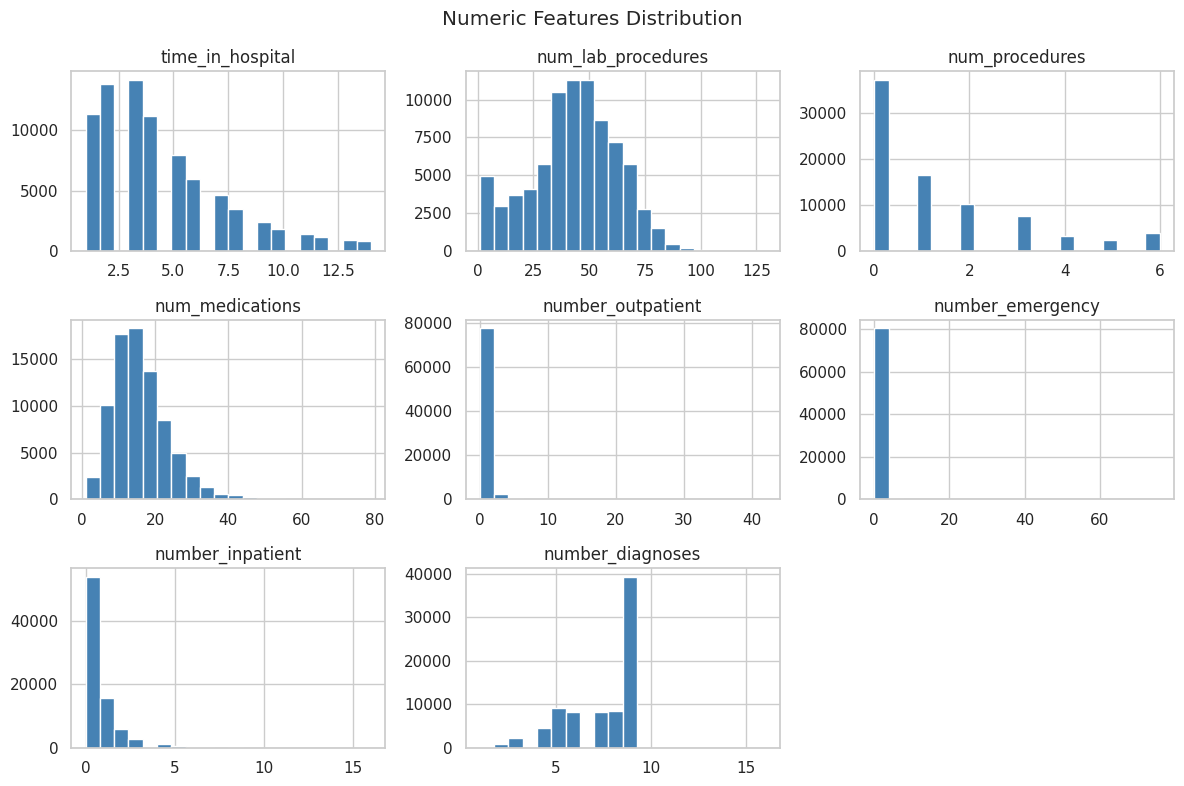

In [7]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_outpatient", "number_emergency",
            "number_inpatient", "number_diagnoses"]

print(df[num_cols].describe().round(2))

df[num_cols].hist(bins=20, figsize=(12, 8), color="steelblue", edgecolor="white")
plt.suptitle("Numeric Features Distribution")
plt.tight_layout()
plt.savefig("numeric_distributions.png", dpi=120)
plt.show()

### 3.6 Medication Columns

In [8]:
med_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
            "glimepiride", "acetohexamide", "glipizide", "glyburide",
            "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
            "miglitol", "troglitazone", "tolazamide", "examide",
            "citoglipton", "insulin", "glyburide-metformin",
            "glipizide-metformin", "glimepiride-pioglitazone",
            "metformin-rosiglitazone", "metformin-pioglitazone"]

print("Metformin value counts:")
print(df["metformin"].value_counts())
print("\nInsulin value counts:")
print(df["insulin"].value_counts())

# Engineered summary features
df["n_meds_changed"] = (df[med_cols].isin(["Up", "Down"])).sum(axis=1)
df["n_meds_steady"]  = (df[med_cols] == "Steady").sum(axis=1)
print("\nMed changes distribution:")
print(df["n_meds_changed"].value_counts().head())

Metformin value counts:
metformin
No        65339
Steady    14630
Up          860
Down        452
Name: count, dtype: int64

Insulin value counts:
insulin
No        38017
Steady    24634
Down       9592
Up         9038
Name: count, dtype: int64

Med changes distribution:
n_meds_changed
0    59311
1    20853
2     1020
3       94
4        3
Name: count, dtype: int64


### 3.7 Early Readmission Rate by Subgroup

Rows after dropping dead/hospice: 79340 (removed 1941)


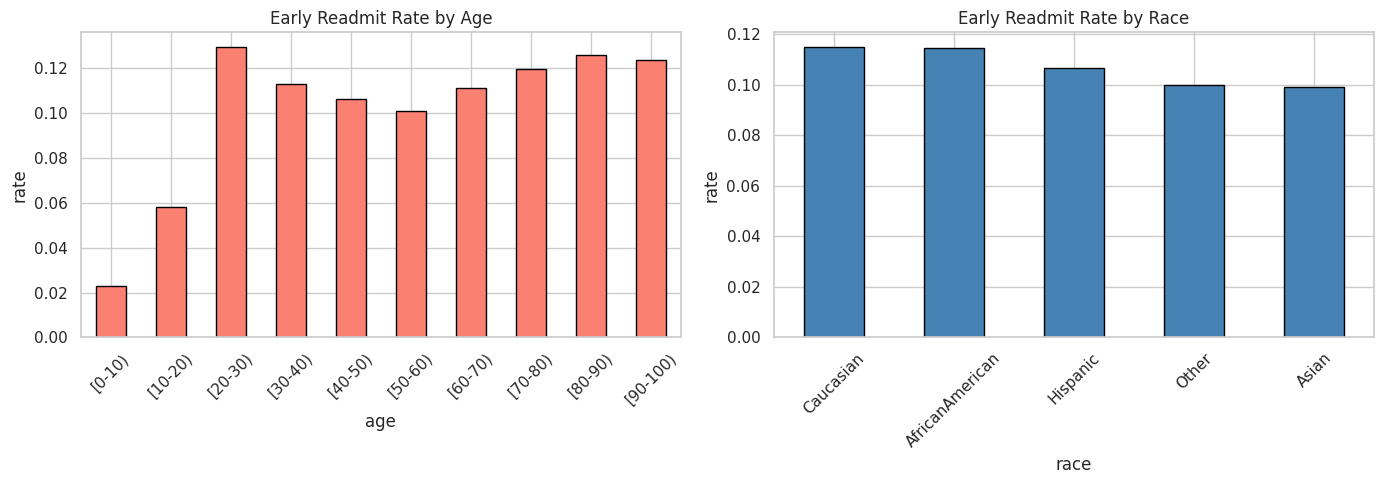


By age:
age
[0-10)      0.023
[10-20)     0.058
[20-30)     0.130
[30-40)     0.113
[40-50)     0.106
[50-60)     0.101
[60-70)     0.111
[70-80)     0.120
[80-90)     0.126
[90-100)    0.124
Name: early_readmit, dtype: float64

By race:
race
AfricanAmerican    0.114
Asian              0.099
Caucasian          0.115
Hispanic           0.107
Other              0.100
Name: early_readmit, dtype: float64

By gender:
gender
Female             0.115
Male               0.112
Unknown/Invalid    0.000
Name: early_readmit, dtype: float64


In [9]:
dead_ids = [11, 13, 14, 19, 20, 21]
df_clean = df[~df["discharge_disposition_id"].isin(dead_ids)].copy()
print(f"Rows after dropping dead/hospice: {len(df_clean)} (removed {len(df)-len(df_clean)})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By age
age_order = ["[0-10)","[10-20)","[20-30)","[30-40)","[40-50)",
             "[50-60)","[60-70)","[70-80)","[80-90)","[90-100)"]
age_rates = df_clean.groupby("age")["early_readmit"].mean().reindex(age_order)
age_rates.plot(kind="bar", color="salmon", edgecolor="black", ax=axes[0])
axes[0].set_title("Early Readmit Rate by Age")
axes[0].set_ylabel("rate")
axes[0].tick_params(axis="x", rotation=45)

# By race
race_rates = df_clean.groupby("race")["early_readmit"].mean().sort_values(ascending=False)
race_rates.plot(kind="bar", color="steelblue", edgecolor="black", ax=axes[1])
axes[1].set_title("Early Readmit Rate by Race")
axes[1].set_ylabel("rate")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("readmit_by_subgroup.png", dpi=120)
plt.show()

print("\nBy age:")
print(df_clean.groupby("age")["early_readmit"].mean().reindex(age_order).round(3))
print("\nBy race:")
print(df_clean.groupby("race")["early_readmit"].mean().round(3))
print("\nBy gender:")
print(df_clean.groupby("gender")["early_readmit"].mean().round(3))

### 3.8 Correlation of Numeric Features with Target

number_inpatient      0.163
number_emergency      0.061
number_diagnoses      0.054
time_in_hospital      0.047
num_medications       0.040
num_lab_procedures    0.024
number_outpatient     0.023
num_procedures       -0.009
Name: early_readmit, dtype: float64


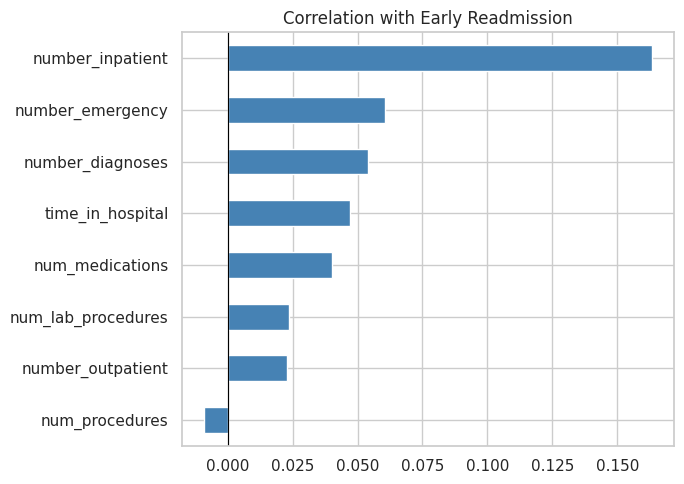

In [10]:
corr = df_clean[num_cols + ["early_readmit"]].corr()["early_readmit"].drop("early_readmit")
print(corr.sort_values(ascending=False).round(3))

corr.sort_values().plot(kind="barh", color="steelblue", figsize=(7, 5))
plt.title("Correlation with Early Readmission")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("correlation.png", dpi=120)
plt.show()

## 4. Preprocessing Pipeline

**Design decisions:**
1. Replace `?` with `NaN`
2. Drop `weight`, `max_glu_serum`, `A1Cresult` (>83% missing), `payer_code` (40% missing, low signal)
3. Drop rows where discharge = dead/hospice (IDs 11,13,14,19,20,21) — these patients cannot be readmitted
4. Map `admission_type_id`, `discharge_disposition_id`, `admission_source_id` to readable strings using `IDS_mapping.csv` values
5. Group `diag_1/2/3` ICD-9 codes into 9 broad categories
6. Convert age brackets to ordinal integers (preserves order)
7. Engineer `n_meds_changed` and `n_meds_steady` as count features
8. Impute: median for numerics, `"Unknown"` for categoricals
9. Encode categoricals with `OrdinalEncoder` using `handle_unknown="use_encoded_value"` so unseen categories in held-out data don't crash the pipeline

In [11]:
ADMISSION_TYPE_MAP = {
    1: "Emergency", 2: "Urgent", 3: "Elective", 4: "Newborn",
    5: "Not Available", 6: "NULL", 7: "Trauma Center", 8: "Not Mapped",
}
DISCHARGE_DISPOSITION_MAP = {
    1: "Discharged to home", 2: "Transferred to short term hospital",
    3: "Transferred to SNF", 4: "Transferred to ICF",
    5: "Transferred to inpatient care", 6: "Home with home health service",
    7: "Left AMA", 8: "Home under IV provider care",
    9: "Admitted as inpatient", 10: "Neonate transferred",
    11: "Expired", 12: "Still patient or outpatient",
    13: "Hospice home", 14: "Hospice medical facility",
    15: "Transferred to swing bed", 16: "Transferred for outpatient services",
    17: "Referred for outpatient services", 18: "NULL",
    19: "Expired at home hospice", 20: "Expired in medical facility hospice",
    21: "Expired place unknown hospice", 22: "Transferred to rehab facility",
    23: "Transferred to long term care", 24: "Transferred to Medicaid nursing facility",
    25: "Not Mapped", 26: "Unknown/Invalid", 27: "Transferred to federal facility",
    28: "Transferred to psychiatric hospital",
    29: "Transferred to Critical Access Hospital",
    30: "Transferred to other health care institution",
}
ADMISSION_SOURCE_MAP = {
    1: "Physician Referral", 2: "Clinic Referral", 3: "HMO Referral",
    4: "Transfer from hospital", 5: "Transfer from SNF",
    6: "Transfer from health care facility", 7: "Emergency Room",
    8: "Court/Law Enforcement", 9: "Not Available",
    10: "Transfer from critical access hospital", 11: "Normal Delivery",
    12: "Premature Delivery", 13: "Sick Baby", 14: "Extramural Birth",
    15: "Not Available", 17: "NULL", 18: "Transfer from Home Health Agency",
    19: "Readmission to Home Health Agency", 20: "Not Mapped",
    21: "Unknown/Invalid", 22: "Transfer from hospital same facility",
    23: "Born inside this hospital", 24: "Born outside this hospital",
    25: "Transfer from Ambulatory Surgery Center", 26: "Transfer from Hospice",
}
AGE_ORDER = ["[0-10)","[10-20)","[20-30)","[30-40)","[40-50)",
             "[50-60)","[60-70)","[70-80)","[80-90)","[90-100)"]
MED_COLS = ["metformin","repaglinide","nateglinide","chlorpropamide",
            "glimepiride","acetohexamide","glipizide","glyburide",
            "tolbutamide","pioglitazone","rosiglitazone","acarbose",
            "miglitol","troglitazone","tolazamide","examide",
            "citoglipton","insulin","glyburide-metformin",
            "glipizide-metformin","glimepiride-pioglitazone",
            "metformin-rosiglitazone","metformin-pioglitazone"]

CATEGORICAL_COLS = [
    "race","gender","admission_type","discharge_disposition","admission_source",
    "medical_specialty","diag_1_group","diag_2_group","diag_3_group",
    "metformin","repaglinide","nateglinide","chlorpropamide","glimepiride",
    "acetohexamide","glipizide","glyburide","tolbutamide","pioglitazone",
    "rosiglitazone","acarbose","miglitol","troglitazone","tolazamide",
    "examide","citoglipton","insulin","glyburide-metformin",
    "glipizide-metformin","glimepiride-pioglitazone",
    "metformin-rosiglitazone","metformin-pioglitazone","change","diabetesMed",
]
NUMERIC_COLS = [
    "age_num","time_in_hospital","num_lab_procedures","num_procedures",
    "num_medications","number_outpatient","number_emergency",
    "number_inpatient","number_diagnoses","n_meds_changed","n_meds_steady",
    "a1c_tested","glucose_tested","a1c_abnormal",
]
FEATURE_COLS = [
    "race","gender","age_num","admission_type","discharge_disposition",
    "admission_source","time_in_hospital","medical_specialty",
    "num_lab_procedures","num_procedures","num_medications",
    "number_outpatient","number_emergency","number_inpatient",
    "diag_1_group","diag_2_group","diag_3_group","number_diagnoses",
    "metformin","repaglinide","nateglinide","chlorpropamide",
    "glimepiride","acetohexamide","glipizide","glyburide",
    "tolbutamide","pioglitazone","rosiglitazone","acarbose",
    "miglitol","troglitazone","tolazamide","examide",
    "citoglipton","insulin","glyburide-metformin","glipizide-metformin",
    "glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone",
    "change","diabetesMed","n_meds_changed","n_meds_steady",
    "a1c_tested", "glucose_tested", "a1c_abnormal",
]

def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.replace("?", np.nan, inplace=True)
    df["diag_1_group"] = df["diag_1"].apply(group_icd9)
    df["diag_2_group"] = df["diag_2"].apply(group_icd9)
    df["diag_3_group"] = df["diag_3"].apply(group_icd9)
    df["n_meds_changed"] = (df[MED_COLS].isin(["Up", "Down"])).sum(axis=1)
    df["n_meds_steady"]  = (df[MED_COLS] == "Steady").sum(axis=1)
    df["admission_type"]        = df["admission_type_id"].map(ADMISSION_TYPE_MAP).fillna("Unknown")
    df["discharge_disposition"] = df["discharge_disposition_id"].map(DISCHARGE_DISPOSITION_MAP).fillna("Unknown")
    df["admission_source"]      = df["admission_source_id"].map(ADMISSION_SOURCE_MAP).fillna("Unknown")
    df["age_num"] = df["age"].map({a: i for i, a in enumerate(AGE_ORDER)})
    df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
    df["a1c_tested"]     = df["A1Cresult"].notna().astype(int)
    df["glucose_tested"] = df["max_glu_serum"].notna().astype(int)
    df["a1c_abnormal"]   = (df["A1Cresult"].isin([">7", ">8"])).astype(int)
    return df[FEATURE_COLS]

print("Preprocessing functions defined.")

Preprocessing functions defined.


## 5. Build Target & Patient-Grouped Split

In [12]:
raw = pd.read_csv(DATA_PATH)
raw.replace("?", np.nan, inplace=True)
raw["early_readmit"] = (raw["readmitted"] == "<30").astype(int)

# Drop dead/hospice — these patients cannot be readmitted
dead_ids = [11, 13, 14, 19, 20, 21]
raw = raw[~raw["discharge_disposition_id"].isin(dead_ids)].copy()
print("After dropping dead/hospice:", raw.shape)

X      = preprocess(raw)
y      = raw["early_readmit"]
groups = raw["patient_nbr"]
print("Feature matrix:", X.shape)

# Patient-grouped split — same patient never appears in both train and val
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(X, y, groups=groups))

X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

print(f"Train: {len(X_train)} rows | Val: {len(X_val)} rows")
print(f"Train positive rate: {y_train.mean():.3f}")
print(f"Val positive rate:   {y_val.mean():.3f}")

# Verify no patient overlap
train_patients = set(groups.iloc[train_idx])
val_patients   = set(groups.iloc[val_idx])
print(f"Patient overlap between train and val: {len(train_patients & val_patients)} (should be 0)")

After dropping dead/hospice: (79340, 51)
Feature matrix: (79340, 48)
Train: 63586 rows | Val: 15754 rows
Train positive rate: 0.114
Val positive rate:   0.111
Patient overlap between train and val: 0 (should be 0)


## 6. Model Training & Comparison

We compare three models ranging from simple (interpretable) to complex (high capacity):
- **Logistic Regression**: linear baseline, interpretable coefficients
- **Random Forest**: non-linear, ensemble of trees, less prone to overfitting than single tree
- **Gradient Boosting**: sequential ensemble, typically strongest on tabular data

All preprocessing (imputation, encoding) is fitted on training data only and applied to validation, no leakage.

In [13]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        encoded_missing_value=-2
    )),
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, NUMERIC_COLS),
    ("cat", categorical_transformer, CATEGORICAL_COLS),
], remainder="drop")

models = {
        "LogisticRegression": LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=42),
        "RandomForest": RandomForestClassifier(
            n_estimators=200, class_weight="balanced", max_depth=15,
            min_samples_leaf=10, random_state=42, n_jobs=-1),
        "GradientBoosting": GradientBoostingClassifier(
            n_estimators=500,      # up from 300
            learning_rate=0.03,    # slower learning to match more trees
            max_depth=4,
            subsample=0.8,
            min_samples_leaf=20,   # prevent overfitting
            random_state=42
        ),
    }

results = {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", model)])
    pipe.fit(X_train, y_train)
    probs = pipe.predict_proba(X_val)[:, 1]
    ap  = average_precision_score(y_val, probs)
    auc = roc_auc_score(y_val, probs)
    bs  = brier_score_loss(y_val, probs)
    results[name] = {"pipeline": pipe, "probs": probs, "AP": ap, "AUC": auc, "Brier": bs}
    print(f"{name:25s}  AP={ap:.4f}  AUC={auc:.4f}  Brier={bs:.4f}")

LogisticRegression         AP=0.1990  AUC=0.6599  Brier=0.2294
RandomForest               AP=0.2014  AUC=0.6627  Brier=0.1813
GradientBoosting           AP=0.2266  AUC=0.6728  Brier=0.0942


### 6.1 Model Comparison Summary

                    Average Precision  ROC-AUC  Brier Score
LogisticRegression             0.1990   0.6599       0.2294
RandomForest                   0.2014   0.6627       0.1813
GradientBoosting               0.2266   0.6728       0.0942


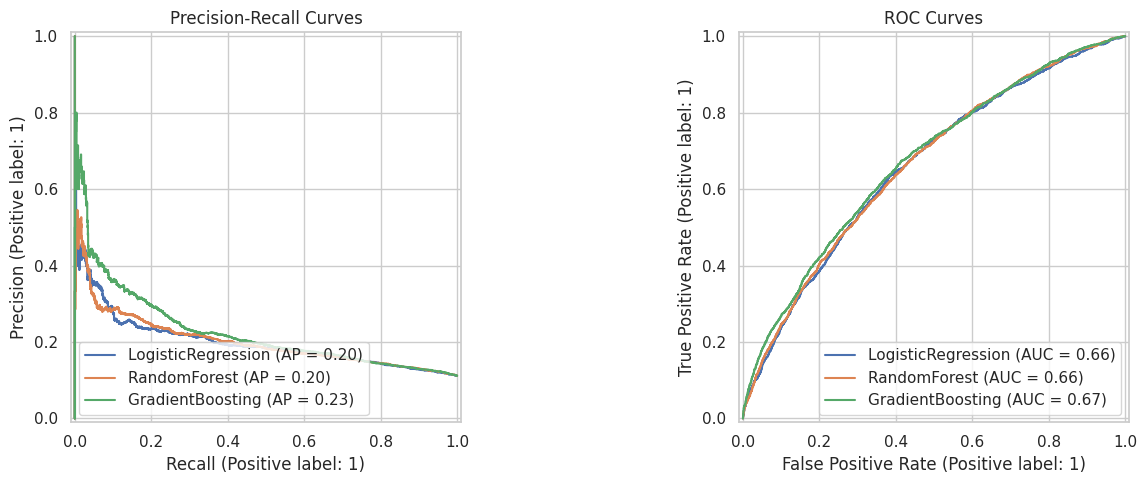

In [14]:
summary = pd.DataFrame({
    name: {"Average Precision": v["AP"], "ROC-AUC": v["AUC"], "Brier Score": v["Brier"]}
    for name, v in results.items()
}).T
print(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, v in results.items():
    PrecisionRecallDisplay.from_predictions(
        y_val, v["probs"], name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(
        y_val, v["probs"], name=name, ax=axes[1])
axes[0].set_title("Precision-Recall Curves")
axes[1].set_title("ROC Curves")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=120)
plt.show()

## 7. Threshold Selection

**Why not 0.5?** With only 11% positive class rate, the model's raw probabilities are naturally low. A 0.5 threshold would flag almost nobody.

**Clinical asymmetry:** Missing a high-risk patient (false negative) is more costly than flagging someone who turns out fine (false positive). We scan thresholds and select by F1, which balances precision and recall, but we also inspect recall to ensure we're catching enough true positives.

Best model: GradientBoosting  (AP=0.2266)


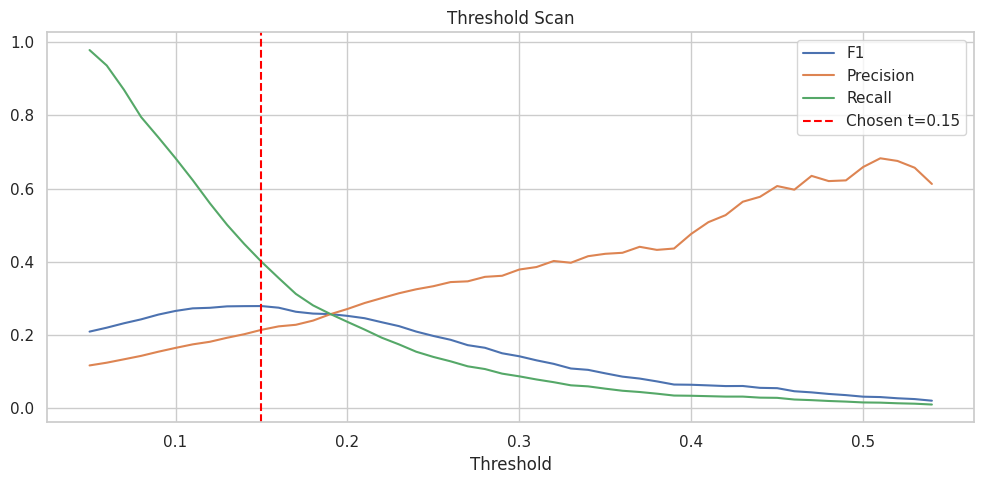


Chosen threshold: 0.15  (F1=0.280)


In [15]:
best_name = max(results, key=lambda k: results[k]["AP"])
best      = results[best_name]
probs_val = best["probs"]
print(f"Best model: {best_name}  (AP={best['AP']:.4f})")

thresholds = np.arange(0.05, 0.55, 0.01)
scan = []
for t in thresholds:
    preds = (probs_val >= t).astype(int)
    scan.append({
        "threshold": round(t, 2),
        "F1":        f1_score(y_val, preds, zero_division=0),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "Recall":    recall_score(y_val, preds, zero_division=0),
    })
scan_df = pd.DataFrame(scan)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(scan_df["threshold"], scan_df["F1"],        label="F1")
ax.plot(scan_df["threshold"], scan_df["Precision"], label="Precision")
ax.plot(scan_df["threshold"], scan_df["Recall"],    label="Recall")
best_t   = scan_df.loc[scan_df["F1"].idxmax(), "threshold"]
best_f1  = scan_df["F1"].max()
ax.axvline(best_t, color="red", linestyle="--", label=f"Chosen t={best_t}")
ax.set_xlabel("Threshold")
ax.set_title("Threshold Scan")
ax.legend()
plt.tight_layout()
plt.savefig("threshold_scan.png", dpi=120)
plt.show()
print(f"\nChosen threshold: {best_t}  (F1={best_f1:.3f})")

In [16]:
preds_final = (probs_val >= best_t).astype(int)
print(classification_report(y_val, preds_final, target_names=["No early", "Early <30"]))

              precision    recall  f1-score   support

    No early       0.92      0.82      0.86     13999
   Early <30       0.21      0.40      0.28      1755

    accuracy                           0.77     15754
   macro avg       0.57      0.61      0.57     15754
weighted avg       0.84      0.77      0.80     15754



## 8. Subgroup Fairness Analysis

We check whether model performance varies across demographic groups. Performance gaps may indicate the model is less reliable for certain populations, which has real clinical consequences.

In [17]:
val_df = raw.iloc[val_idx].copy()
val_df["prob"] = probs_val

for group_col in ["age", "race", "gender"]:
    print(f"\n--- Subgroup: {group_col} ---")
    rows = []
    for grp in sorted(val_df[group_col].dropna().unique()):
        sub = val_df[val_df[group_col] == grp]
        if len(sub) < 20:
            continue
        ap = average_precision_score(sub["early_readmit"], sub["prob"])
        rows.append({group_col: grp, "n": len(sub), "AP": round(ap, 3)})
    print(pd.DataFrame(rows).to_string(index=False))


--- Subgroup: age ---
     age    n    AP
  [0-10)   28 0.067
 [10-20)  127 0.232
 [20-30)  214 0.405
 [30-40)  611 0.348
 [40-50) 1478 0.357
 [50-60) 2700 0.198
 [60-70) 3506 0.210
 [70-80) 4121 0.199
 [80-90) 2582 0.224
[90-100)  387 0.178

--- Subgroup: race ---
           race     n    AP
AfricanAmerican  3001 0.230
          Asian    88 0.330
      Caucasian 11809 0.223
       Hispanic   328 0.415
          Other   178 0.213

--- Subgroup: gender ---
gender    n    AP
Female 8301 0.217
  Male 7453 0.239


## 9. Save Model & Threshold

In [18]:
pipeline_path = os.path.join(MODEL_DIR, "pipeline.joblib")
joblib.dump(best["pipeline"], pipeline_path)
print(f"Model saved: {pipeline_path}")

with open("threshold.json", "w") as f:
    json.dump({"threshold": round(float(best_t), 2)}, f, indent=2)
print(f"Threshold saved: threshold.json  ({best_t})")

meta_path = os.path.join(MODEL_DIR, "feature_meta.json")
with open(meta_path, "w") as f:
    json.dump({"numeric": NUMERIC_COLS, "categorical": CATEGORICAL_COLS}, f, indent=2)
print(f"Feature meta saved: {meta_path}")

Model saved: model/pipeline.joblib
Threshold saved: threshold.json  (0.15)
Feature meta saved: model/feature_meta.json
